# InstructGPT 복습 실습 — SFT → 보상 모델 → PPO
**Euron · 논문스터디 | 학생용 | Colab CPU | 풀이 목표 60–90분**

이 실습은 “SFT 이후에도 왜 사람의 선호를 이용해 정책을 바꾸는가?”를 확인합니다.
질문별 네 개의 후보 답변을 선택하는 작은 모델을 직접 학습합니다.

**학생용:** TODO 1–6을 채우고 해석 질문 3개에 답하세요. 빈칸 셀은 미완성 상태에서 의도적으로 멈춥니다. 학습 반복문·그래프 코드는 제공됩니다.

### 학습 목표
1. 모범 답변을 모방하는 SFT와 선호 쌍으로 학습하는 보상 모델의 차이를 설명한다.
2. PPO의 확률비·advantage·clipping과 SFT 기준 정책에 대한 KL을 구분한다.
3. KL 계수와 선호 데이터의 편향이 결과에 미치는 영향을 비교한다.

### 먼저 알아둘 단순화
| 논문의 구성 | 이 실습의 구성 |
|---|---|
| 사전 학습된 GPT-3의 토큰 생성 | 질문마다 4개 후보를 선택하는 표 형태 정책; 사전 학습 없음 |
| 질문·답변 텍스트를 읽는 보상 모델 | 질문의 대상과 답변의 수작업 특성을 입력받는 선형 보상 모델 |
| 실제 사람의 시연·순위 평가 | 교육용으로 만든 시연과 합성 선호 쌍 |
| 여러 토큰의 trajectory·value·GAE | 한 번 선택하고 끝나는 contextual bandit; advantage = reward − value |
| 샘플별 KL 패널티를 포함한 보상 | 후보가 4개이므로 정확한 KL을 계산해 actor 손실에 추가 |
| PPO-ptx의 사전 학습 데이터 혼합 | 포함하지 않음; KL은 PPO-ptx의 대체가 아님 |

**논문 결과 재현이나 언어모델 성능 평가가 아닙니다.** 정확성·대상 적합성 특성도 사람이 미리 제공하므로,
실제 텍스트에서 자동으로 사실을 판별하는 시스템이 아닙니다.


## 0. Colab 실행 준비
1. Colab의 **파일 → 노트북 업로드**에서 이 파일을 선택합니다.
2. **런타임 → 런타임 유형 변경 → Python 3 / CPU**로 설정합니다. GPU는 필요하지 않습니다.
3. 위에서부터 실행합니다. 학생용은 TODO를 풀고 다음 단계로 이동합니다.

데이터는 노트북에 포함되어 있습니다. API 키, Drive 연결, 외부 모델 다운로드가 필요하지 않습니다.
아래 셀은 패키지가 없을 때만 설치합니다. 이미 설치된 Colab 패키지는 그대로 사용합니다.


In [1]:
import importlib.util
import subprocess
import sys
required = ['torch', 'numpy', 'pandas', 'matplotlib']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

import copy
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from IPython.display import display

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
torch.set_num_threads(1)
DEVICE = torch.device('cpu')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#006747', '#CF8C24', '#467AA4', '#8F5C79']
# 그래프는 영문 레이블: Colab에서 별도 한글 폰트 설치 없이 표시합니다.
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__)
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| device:', DEVICE)


Python: 3.10.20 | PyTorch: 2.5.1
NumPy: 2.2.5 | pandas: 2.3.3 | device: cpu


## 1. 데이터 — 시연과 선호 쌍은 다른 정보입니다
총 **12개 질문 × 4개 후보**를 사용합니다. 각 질문에는 대상에 맞는 답변, 다른 대상에 맞는 답변,
길지만 틀린 답변, 무관한 답변이 있습니다. 후보 순서를 질문마다 섞어 위치만 보고 맞힐 수 없게 합니다.

시연 데이터에는 두 종류의 정확한 답변을 섞습니다. 일부는 요청한 대상에 충분히 맞지 않습니다.
이는 SFT와 선호 학습의 차이를 보이기 위해 의도적으로 구성한 불완전한 시연입니다.
실제 InstructGPT의 시연 데이터를 의미하지 않습니다.

보상 모델 특성은 `[정확성, 관련성, 대상 적합성, 길이]`입니다.
대상 적합성은 **질문의 요청 대상과 답변의 설명 수준을 함께** 고려한 수작업 특성입니다.


In [2]:
topics = [
    ('중력', '물건을 지구 쪽으로 끌어당기는 힘이야.',
     '중력은 질량을 가진 물체 사이의 인력이다. 지표면 부근의 자유 낙하 가속도는 약 9.8 m/s²이다.',
     '중력은 모든 물체를 지구 밖으로 밀어내는 힘이다.'),
    ('광합성', '식물이 햇빛을 이용해 먹이를 만드는 과정이야.',
     '광합성은 빛 에너지를 화학 에너지로 전환하는 과정이다. 식물은 이산화탄소와 물을 이용해 유기물을 합성한다.',
     '광합성은 식물이 햇빛 없이 돌을 먹고 산소를 없애는 과정이다.'),
    ('증발', '물이 표면에서 수증기로 바뀌는 일이야.',
     '증발은 액체 표면의 분자가 기체상으로 이동하는 현상이다. 끓는점 이하에서도 일어날 수 있다.',
     '증발은 물이 항상 얼음으로 변하는 과정이며 끓을 때만 일어난다.'),
    ('전기 회로', '전기가 흐를 수 있도록 이어진 길이야.',
     '전기 회로는 전류가 흐를 수 있는 연결 구조다. 직류 회로에서 지속적인 전류가 흐르려면 폐회로가 필요하다.',
     '전류는 선이 완전히 끊어져 있어야만 계속 흐를 수 있다.'),
    ('확률', '어떤 일이 일어날 가능성을 숫자로 나타낸 거야.',
     '확률은 사건의 발생 가능성을 나타내는 측도다. 전체 표본 공간의 확률은 1이며 각 사건의 확률은 0과 1 사이이다.',
     '확률은 반드시 2보다 큰 수이며 불가능한 사건의 확률은 5이다.'),
    ('평균', '수들을 모두 더한 다음 수의 개수로 나눈 값이야.',
     '산술평균은 관측값의 합을 관측값 개수로 나눈 값이다. 이상치에 영향을 받으므로 중앙값과 함께 해석할 수 있다.',
     '산술평균은 모든 수를 곱한 뒤 가장 큰 수로 나눈 값이다.'),
    ('밀도', '같은 크기 안에 물질이 얼마나 들어 있는지를 나타내.',
     '밀도는 단위 부피당 질량이다. 균일한 물체의 밀도는 질량을 부피로 나누어 계산한다.',
     '밀도는 부피를 질량에 더한 값이며 단위가 전혀 없다.'),
    ('마찰', '서로 닿은 물체가 미끄러지는 것을 방해하는 힘이야.',
     '마찰력은 접촉면의 상대 운동 또는 운동하려는 경향에 저항하는 힘이다. 정지 마찰과 운동 마찰을 구분한다.',
     '마찰력은 모든 상황에서 접촉면과 떨어진 물체를 같은 방향으로 가속한다.'),
    ('소리', '물체의 떨림이 공기 같은 물질을 통해 전달되는 거야.',
     '소리는 매질을 통해 전파되는 기계적 파동이다. 진공에서는 매질이 없어 소리가 전달되지 않는다.',
     '소리는 진공에서만 전달되고 공기에서는 절대로 전달되지 않는다.'),
    ('분수', '전체를 같은 크기로 나눈 조각이 몇 개인지 나타내.',
     '분수 a/b는 b가 0이 아닐 때 수의 비를 표현한다. 분모는 나눈 단위와 관련되며 분자는 그 단위의 개수를 나타낸다.',
     '분수의 분모는 반드시 0이어야 하고 분자는 항상 분모보다 크다.'),
    ('온도', '얼마나 뜨겁거나 차가운지를 나타내는 값이야.',
     '온도는 열평형과 관련된 상태량이다. 온도와 물체의 전체 열에너지 또는 전달된 열량은 구별해야 한다.',
     '온도는 물체의 색깔만으로 정해지며 열과 아무 관련이 없다.'),
    ('자석', '철 같은 물질을 끌어당길 수 있는 물건이야.',
     '자석은 자기장을 만드는 물체다. 자극에는 N극과 S극이 있으며 같은 극은 밀어내고 다른 극은 끌어당긴다.',
     '자석의 같은 극끼리는 항상 끌어당기며 모든 플라스틱은 철보다 강하게 붙는다.'),
]
records = []
features, good_ids, other_ids, wrong_ids = [], [], [], []
all_answers = []
for q, (topic, simple, detailed, false_claim) in enumerate(topics):
    audience = '초등학생' if q % 2 == 0 else '대학생'
    particle = '을' if (ord(topic[-1]) - 0xAC00) % 28 else '를'
    prompt = f'{audience}에게 {topic}{particle} 설명해줘.'
    good, other = (simple, detailed) if audience == '초등학생' else (detailed, simple)
    verbose_wrong = false_claim + ' ' + false_claim + ' 따라서 위 주장은 언제나 확실하며 예외도 없다. 이 설명을 반복하면 더 정확한 답이 된다.'
    unrelated = '오늘 저녁에는 밥과 반찬을 준비하고 식탁을 정리하면 좋겠습니다.'
    candidates = [good, other, verbose_wrong, unrelated]
    # 후보 ID는 정답 유형을 뜻하지 않습니다.
    order = np.random.default_rng(SEED + q).permutation(4)
    answers = [candidates[i] for i in order]
    base = np.array([[1, 1, 1, 0], [1, 1, .35, 0],
                     [0, 1, .65, 0], [0, 0, .1, 0]], dtype=np.float32)
    feature = base[order].copy()
    feature[:, 3] = [len(a) for a in answers]
    features.append(feature)
    good_ids.append(int(np.where(order == 0)[0][0]))
    other_ids.append(int(np.where(order == 1)[0][0]))
    wrong_ids.append(int(np.where(order == 2)[0][0]))
    all_answers.append(answers)
    records.append({'qid': q, 'prompt': prompt, 'audience': audience})

X = torch.tensor(np.stack(features), device=DEVICE)
X[:, :, 3] /= X[:, :, 3].max()  # 전체 데이터에서 고정한 문자 수 척도
N_Q, N_A, N_F = X.shape
good_ids = torch.tensor(good_ids)
wrong_ids = torch.tensor(wrong_ids)
train_q = torch.arange(8)
heldout_q = torch.arange(8, 12)
feature_names = ['correctness', 'relevance', 'audience_match', 'length']

# 평가용 합성 기준 점수. PPO는 이 값을 직접 보상으로 쓰지 않습니다.
rubric_raw = 2 * X[:, :, 0] + X[:, :, 1] + 1.2 * X[:, :, 2] - .4 * X[:, :, 3]
rubric = (rubric_raw + .4) / 4.6  # [0, 1]の教育用スコア
length_biased_labels = rubric_raw + 6 * X[:, :, 3]

demo_q, demo_a = [], []
for q in range(N_Q):
    demo_q.extend([q] * 20)
    demo_a.extend([int(good_ids[q])] * 9 + [other_ids[q]] * 11)
demo_q = torch.tensor(demo_q)
demo_a = torch.tensor(demo_a)

def make_pairs(qids, label_scores):
    result = []
    for q in qids.tolist():
        for a in range(N_A):
            for b in range(a + 1, N_A):
                if abs(float(label_scores[q, a] - label_scores[q, b])) < 1e-6:
                    continue
                winner, loser = (a, b) if label_scores[q, a] > label_scores[q, b] else (b, a)
                result.append((q, winner, loser))
    return torch.tensor(result, dtype=torch.long)

clean_train = make_pairs(train_q, rubric_raw)
clean_test = make_pairs(heldout_q, rubric_raw)
biased_train = make_pairs(train_q, length_biased_labels)
biased_test = make_pairs(heldout_q, length_biased_labels)
assert set(train_q.tolist()).isdisjoint(set(heldout_q.tolist()))
display(pd.DataFrame(records))
print(f'SFT: {len(demo_q)} demonstrations | RM train: {len(clean_train)} pairs | held-out: {len(clean_test)} pairs')


,qid,prompt,audience
0,0,초등학생에게 중력을 설명해줘.,초등학생
1,1,대학생에게 광합성을 설명해줘.,대학생
2,2,초등학생에게 증발을 설명해줘.,초등학생
3,3,대학생에게 전기 회로를 설명해줘.,대학생
4,4,초등학생에게 확률을 설명해줘.,초등학생
5,5,대학생에게 평균을 설명해줘.,대학생
6,6,초등학생에게 밀도를 설명해줘.,초등학생
7,7,대학생에게 마찰을 설명해줘.,대학생
8,8,초등학생에게 소리를 설명해줘.,초등학생
9,9,대학생에게 분수를 설명해줘.,대학생


SFT: 240 demonstrations | RM train: 48 pairs | held-out: 24 pairs


In [3]:
def show_candidates(q):
    from IPython.display import Markdown
    lines = [f"**질문 {q}: {records[q]['prompt']}**"]
    lines += [f'- **후보 {a}:** {answer}' for a, answer in enumerate(all_answers[q])]
    display(Markdown('\n\n'.join(lines)))

q = 0  # 다른 질문을 보려면 0~11로 변경
show_candidates(q)
preview = []
for a in range(N_A):
    row = {'candidate': a}
    row.update(dict(zip(feature_names, X[q, a].tolist())))
    preview.append(row)
display(pd.DataFrame(preview))
print('SFT demonstration counts:', torch.bincount(demo_a[demo_q == q], minlength=N_A).tolist())


**질문 0: 초등학생에게 중력을 설명해줘.**

- **후보 0:** 오늘 저녁에는 밥과 반찬을 준비하고 식탁을 정리하면 좋겠습니다.

- **후보 1:** 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 따라서 위 주장은 언제나 확실하며 예외도 없다. 이 설명을 반복하면 더 정확한 답이 된다.

- **후보 2:** 중력은 질량을 가진 물체 사이의 인력이다. 지표면 부근의 자유 낙하 가속도는 약 9.8 m/s²이다.

- **후보 3:** 물건을 지구 쪽으로 끌어당기는 힘이야.

,candidate,correctness,relevance,audience_match,length
0,0,0.0,0.0,0.10,0.257353
1,1,0.0,1.0,0.65,0.779412
2,2,1.0,1.0,0.35,0.411765
3,3,1.0,1.0,1.00,0.154412


SFT demonstration counts: [0, 0, 11, 9]


### 생각해보기
같은 질문에서 “모범 답변 하나”와 “두 답변 중 무엇이 더 좋은가”는 어떤 정보를 제공하나요?
보상 모델의 테스트 질문 4개는 학습 질문과 분리되어 있지만, **같은 합성 규칙으로 생성**되었습니다.
이 테스트의 성공이 실제 사람의 다양한 선호나 새로운 분야에 대한 일반화를 보장할까요?


## 2. SFT — 시연 답변의 확률을 높이기
정책의 파라미터는 `logits[질문, 후보]`입니다. softmax를 적용하면 후보별 선택 확률이 됩니다.
이 모델은 주어진 질문 ID만 다루며 새 질문에 일반화하는 언어모델이 아닙니다.

**TODO 1 · 5분**: 시연 답변 ID를 정답으로 하는 교차 엔트로피를 반환하세요.
입력 크기는 `[시연 수, 4]`, 정답 크기는 `[시연 수]`입니다. `F.cross_entropy`를 사용합니다.

$$
L_{SFT}=-\mathbb{E}_{(x,y)\sim D_{demo}}\log\pi(y|x)
$$


In [4]:
def sft_loss(batch_logits, target_ids):
    # TODO 1: F.cross_entropy로 scalar loss를 반환하세요.
    return F.cross_entropy(batch_logits, target_ids)

check_logits = torch.zeros(3, 4)
assert torch.allclose(sft_loss(check_logits, torch.tensor([0, 1, 2])),
                      torch.tensor(np.log(4), dtype=torch.float32), atol=1e-5)
print('TODO 1 passed')


TODO 1 passed


In [5]:
set_seed()
policy_logits = nn.Parameter(torch.zeros(N_Q, N_A))
sft_optimizer = torch.optim.Adam([policy_logits], lr=.06)
sft_history = []
for step in range(35):
    loss = sft_loss(policy_logits[demo_q], demo_a)
    sft_optimizer.zero_grad()
    loss.backward()
    sft_optimizer.step()
    sft_history.append(float(loss.detach()))

reference_logits = policy_logits.detach().clone()  # SFT 이후 고정: PPO 전체의 기준 정책
reference_logp = F.log_softmax(reference_logits, dim=-1)
reference_probs = reference_logp.exp()
assert not reference_logits.requires_grad
print(f'SFT CE: {sft_history[0]:.3f} → {sft_history[-1]:.3f}')
display(pd.DataFrame({'candidate': range(N_A), 'SFT probability': reference_probs[0].tolist()}))


SFT CE: 1.386 → 0.736


,candidate,SFT probability
0,0,0.022534
1,1,0.022534
2,2,0.527715
3,3,0.427217


## 3. 보상 모델 — 선호 쌍을 점수 차이로 학습
보상 모델은 `r(x,y) = wᵀ feature(x,y)`입니다.
선호 답변과 비선호 답변의 **점수 차이**로 확률을 계산합니다. 보상 점수 자체는 확률이 아닙니다.

**TODO 2 · 10분**: 아래 pairwise loss를 구현하세요. `F.logsigmoid` 또는 `F.softplus`를 쓰면 수치적으로 안정적입니다.
`chosen_scores`와 `rejected_scores`는 각각 `[쌍 수]`입니다.

$$
L_{RM}=-\mathbb{E}\log\sigma(r(x,y_{chosen})-r(x,y_{rejected}))
$$

학습에는 8개 질문만 사용합니다. L2 정규화는 작은 합성 데이터에서 점수가 과도하게 커지는 것을 줄입니다.


In [6]:
def preference_loss(chosen_scores, rejected_scores):
    # TODO 2: 선호 답변의 점수가 클수록 작아지는 scalar loss를 반환하세요.
    return -F.logsigmoid(chosen_scores - rejected_scores).mean()

equal = preference_loss(torch.zeros(3), torch.zeros(3))
better = preference_loss(torch.ones(3), torch.zeros(3))
assert abs(float(equal) - np.log(2)) < 1e-5
assert float(better) < float(equal)
print('TODO 2 passed')


TODO 2 passed


RM regularized loss: 0.693 → 0.266


,split,pairs,pair accuracy
0,train (8 prompts),48,1.0
1,held-out (4 prompts),24,1.0


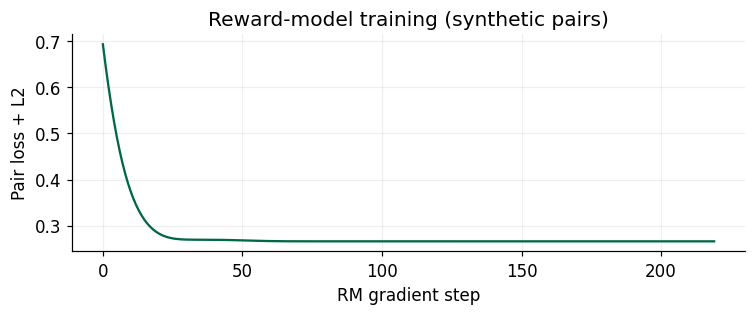

In [7]:
def train_reward_model(pairs, steps=220):
    set_seed()
    model = nn.Linear(N_F, 1, bias=False)
    nn.init.zeros_(model.weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=.06)
    q, chosen, rejected = pairs.T
    history = []
    for _ in range(steps):
        scores = model(X).squeeze(-1)
        loss = preference_loss(scores[q, chosen], scores[q, rejected])
        loss = loss + .02 * model.weight.square().sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    model.eval()
    model.requires_grad_(False)
    with torch.no_grad():
        raw_scores = model(X).squeeze(-1)
        # 학습 질문에서만 정한 척도를 전체 질문에 고정 적용
        mean = raw_scores[train_q].mean()
        scale = raw_scores[train_q].std().clamp_min(1e-6)
        scores = (raw_scores - mean) / scale
    return model, scores, history

def pair_accuracy(scores, pairs):
    q, chosen, rejected = pairs.T
    return float((scores[q, chosen] > scores[q, rejected]).float().mean())

clean_rm, clean_rewards, rm_history = train_reward_model(clean_train)
print(f'RM regularized loss: {rm_history[0]:.3f} → {rm_history[-1]:.3f}')
display(pd.DataFrame([{'split': 'train (8 prompts)', 'pairs': len(clean_train),
                       'pair accuracy': pair_accuracy(clean_rewards, clean_train)},
                      {'split': 'held-out (4 prompts)', 'pairs': len(clean_test),
                       'pair accuracy': pair_accuracy(clean_rewards, clean_test)}]))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(rm_history, color=COLORS[0])
ax.set(xlabel='RM gradient step', ylabel='Pair loss + L2', title='Reward-model training (synthetic pairs)')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 4. PPO — 한 번의 선택에 대한 업데이트
한 질문에서 후보 하나를 선택하고 종료하므로 이 실습에서는 할인된 미래 보상이 없습니다.
critic의 `V(x)`는 해당 질문에서 얻을 보상의 기대값을 추정합니다.
critic은 선택 답변을 입력받지 않고 **질문만** 입력받습니다.

**TODO 3 · 5분**: 확률비 `ratio = exp(new_logp − old_logp)`를 구현하세요.

**TODO 4 · 10분**: 아래 clipped objective의 평균을 반환하세요. optimizer는 최소화하므로 학습 코드에서 음수를 취합니다.

$$
L^{CLIP}=\mathbb{E}\min(\rho A,\operatorname{clip}(\rho,1-\epsilon,1+\epsilon)A)
$$

**TODO 5 · 5분**: `advantage = reward − value`를 구현하세요. 이 값은 policy 업데이트 중 고정합니다.

**TODO 6 · 10분**: 각 질문의 `KL(현재 정책 || SFT 정책)`을 정확히 계산하세요.
`logp`, `ref_logp`는 `[질문 수, 4]`; 반환값은 `[질문 수]`입니다.

$$
KL(\pi\|\pi_{SFT})=\sum_a\pi(a|x)(\log\pi(a|x)-\log\pi_{SFT}(a|x))
$$

**두 기준을 구별하세요.** `old_logp`는 매 rollout 시작 시 고정하고 다음 rollout에서 갱신합니다.
`ref_logp`는 SFT 직후 고정하고 PPO 학습 내내 유지합니다.
clipping은 확률비를 강제로 범위 안에 가두는 제약이 아닙니다.


In [8]:
def probability_ratio(new_logp, old_logp):
    # TODO 3: 로그 확률의 차이로 확률비를 반환하세요.
    return torch.exp(new_logp - old_logp)

def clipped_objective(ratio, advantage, epsilon=.2):
    # TODO 4: 원래 항과 clipped 항 중 작은 값을 선택하고 평균하세요.
    unclipped = ratio * advantage
    clipped = torch.clamp(ratio, 1 - epsilon, 1 + epsilon) * advantage
    return torch.min(unclipped, clipped).mean()

def bandit_advantage(reward, value):
    # TODO 5: 한 단계 bandit의 advantage를 반환하세요.
    return reward - value

def categorical_kl(logp, ref_logp):
    # TODO 6: 마지막 차원(후보)을 합해 질문별 KL을 반환하세요.
    return (logp.exp() * (logp - ref_logp)).sum(-1)


### 함수 검증
특히 **음수 advantage**인 경우에도 최소값을 선택하는지 확인하세요.
`min`을 `max`로 바꾸면 나쁜 행동의 확률을 줄이는 방향에서도 clipping 동작이 달라집니다.


In [9]:
assert torch.allclose(probability_ratio(torch.tensor([-.3]), torch.tensor([-.3])), torch.ones(1))
assert torch.allclose(probability_ratio(torch.tensor([np.log(.6)]), torch.tensor([np.log(.3)])),
                      torch.tensor([2.], dtype=torch.float64))
value = clipped_objective(torch.tensor([1.5, .5]), torch.tensor([1., -1.]))
assert abs(float(value) - .2) < 1e-6
assert torch.allclose(bandit_advantage(torch.tensor([2., 0.]), torch.tensor([.5, .5])),
                      torch.tensor([1.5, -.5]))
uniform = torch.full((2, 4), .25).log()
assert torch.allclose(categorical_kl(uniform, uniform), torch.zeros(2), atol=1e-6)
p = torch.tensor([[.7, .1, .1, .1]])
q = torch.tensor([[.25, .25, .25, .25]])
expected_kl = float(.7 * np.log(.7 / .25) + .3 * np.log(.1 / .25))
assert abs(float(categorical_kl(p.log(), q.log())[0]) - expected_kl) < 1e-6
print('TODO 3–6 passed')


TODO 3–6 passed


### 제공 코드 — rollout, actor, critic
아래 학습 루프는 제공합니다. `β`는 KL 패널티 계수입니다.

$$
L_{total}=-L^{CLIP}+\beta\,\mathbb{E}_x KL(\pi\|\pi_{SFT})+0.5\,\mathbb{E}(V(x)-r)^2
$$

이 실습은 전체 4개 후보의 KL을 actor 손실에서 미분합니다. 논문의 샘플별 KL 보상 shaping을
그대로 구현한 코드는 아닙니다. critic도 여기서는 KL을 제외한 RM 보상을 예측합니다.
보상 모델과 SFT 기준 정책은 고정하고, actor와 critic만 학습합니다.
각 실험은 같은 SFT 파라미터와 seed에서 독립적으로 시작합니다.


In [10]:
@torch.no_grad()
def measure(logits, rewards, beta):
    logp = F.log_softmax(logits, dim=-1)
    probs = logp.exp()
    kl = categorical_kl(logp, reference_logp).mean()
    expected_reward = (probs * rewards).sum(-1).mean()
    return {'reward': float(expected_reward), 'kl': float(kl),
            'rubric': float((probs * rubric).sum(-1).mean()),
            'length': float((probs * X[:, :, 3]).sum(-1).mean()),
            'wrong_prob': float(probs[torch.arange(N_Q), wrong_ids].mean()),
            'objective': float(expected_reward - beta * kl)}

def run_ppo(rewards, beta=.25, steps=80, rollout_per_prompt=32,
            epochs=4, epsilon=.2, seed=SEED):
    set_seed(seed)
    actor = nn.Parameter(reference_logits.clone())
    critic = nn.Parameter(torch.zeros(N_Q))
    optimizer = torch.optim.Adam([actor, critic], lr=.04)
    history = [{'step': 0, **measure(actor, rewards, beta)}]
    qids = torch.arange(N_Q).repeat_interleave(rollout_per_prompt)
    for step in range(1, steps + 1):
        with torch.no_grad():
            old_logp_all = F.log_softmax(actor, dim=-1).clone()
            dist = torch.distributions.Categorical(logits=actor[qids])
            actions = dist.sample()
            old_logp = old_logp_all[qids, actions]
            selected_rewards = rewards[qids, actions].detach()
            advantages = bandit_advantage(selected_rewards, critic[qids]).detach()
        for _ in range(epochs):
            new_logp_all = F.log_softmax(actor, dim=-1)
            new_logp = new_logp_all[qids, actions]
            ratios = probability_ratio(new_logp, old_logp)
            actor_loss = -clipped_objective(ratios, advantages, epsilon)
            kl_loss = categorical_kl(new_logp_all, reference_logp).mean()
            value_loss = F.mse_loss(critic[qids], selected_rewards)
            loss = actor_loss + beta * kl_loss + .5 * value_loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_([actor, critic], 1.)
            optimizer.step()
        history.append({'step': step, **measure(actor, rewards, beta)})
    return {'logits': actor.detach().clone(), 'history': pd.DataFrame(history),
            'beta': beta, 'rewards': rewards}

betas = [0., .25, 2.]
clean_runs = {beta: run_ppo(clean_rewards, beta=beta) for beta in betas}
summary_rows = [{'model': 'SFT', 'beta': np.nan, **measure(reference_logits, clean_rewards, 0.)}]
for beta, run in clean_runs.items():
    summary_rows.append({'model': 'PPO', 'beta': beta, **measure(run['logits'], clean_rewards, beta)})
clean_summary = pd.DataFrame(summary_rows)
display(clean_summary.round(4))
print('각 값은 12개 질문을 동일 가중한 기대값입니다. 답변 샘플 1개의 점수가 아닙니다.')


,model,beta,reward,kl,rubric,length,wrong_prob,objective
0,SFT,NaN,0.7747,0.0000,0.8514,0.3136,0.0225,0.7747
1,PPO,0.00,1.1621,0.8275,0.9719,0.3132,0.0003,1.1621
2,PPO,0.25,1.1070,0.5101,0.9555,0.3090,0.0010,0.9795
3,PPO,2.00,0.8624,0.0226,0.8805,0.3095,0.0129,0.8171


각 값은 12개 질문을 동일 가중한 기대값입니다. 답변 샘플 1개의 점수가 아닙니다.


## 5. 실험 A — KL 계수를 바꾸면?
세 실험에서 바뀌는 것은 `beta`뿐입니다. 아래 그래프의 보상은 동일한 clean RM의 고정된 척도입니다.
KL은 자연로그를 사용하는 **nats** 단위입니다.
rubric은 생성 시 정한 합성 기준 점수이며 실제 사람의 평가가 아닙니다.
정책 평가에는 PPO가 업데이트한 동일한 12개 질문을 사용합니다. 새로운 질문에 대한 일반화 평가는 아닙니다.


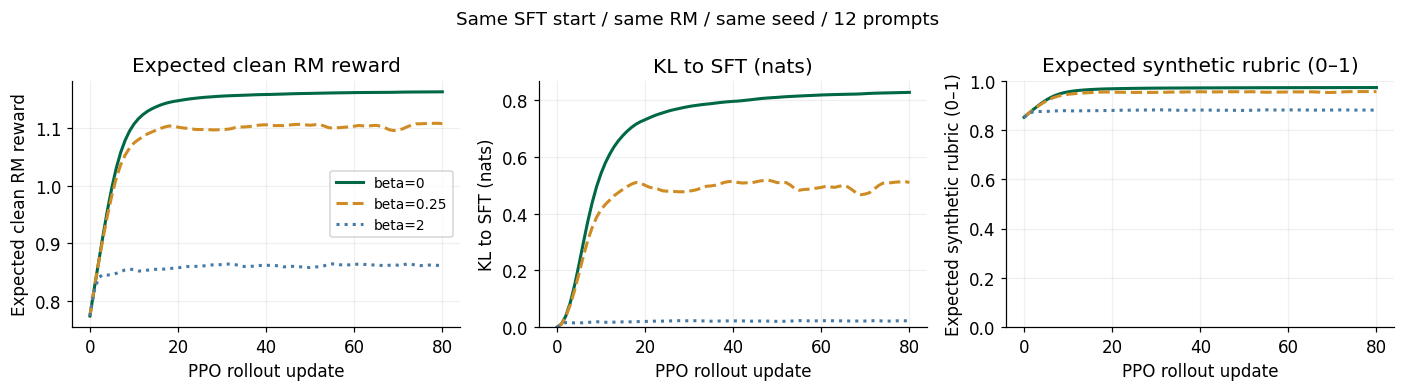

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
metrics = [('reward', 'Expected clean RM reward'), ('kl', 'KL to SFT (nats)'),
           ('rubric', 'Expected synthetic rubric (0–1)')]
styles = ['-', '--', ':']
for i, beta in enumerate(betas):
    hist = clean_runs[beta]['history']
    for ax, (metric, title) in zip(axes, metrics):
        ax.plot(hist['step'], hist[metric], color=COLORS[i], linestyle=styles[i],
                linewidth=2, label=f'beta={beta:g}')
        ax.set(xlabel='PPO rollout update', ylabel=title, title=title)
        ax.grid(alpha=.2)
axes[1].set_ylim(bottom=0)
axes[2].set_ylim(0, 1)
axes[0].legend(fontsize=9)
fig.suptitle('Same SFT start / same RM / same seed / 12 prompts', fontsize=12)
plt.tight_layout()
plt.show()


**질문 0: 초등학생에게 중력을 설명해줘.**

- **후보 0:** 오늘 저녁에는 밥과 반찬을 준비하고 식탁을 정리하면 좋겠습니다.

- **후보 1:** 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 따라서 위 주장은 언제나 확실하며 예외도 없다. 이 설명을 반복하면 더 정확한 답이 된다.

- **후보 2:** 중력은 질량을 가진 물체 사이의 인력이다. 지표면 부근의 자유 낙하 가속도는 약 9.8 m/s²이다.

- **후보 3:** 물건을 지구 쪽으로 끌어당기는 힘이야.

,candidate,SFT,PPO beta=0,PPO beta=0.25,PPO beta=2
0,0,0.023,0.000,0.000,0.007
1,1,0.023,0.000,0.001,0.017
2,2,0.528,0.002,0.086,0.463
3,3,0.427,0.998,0.913,0.513


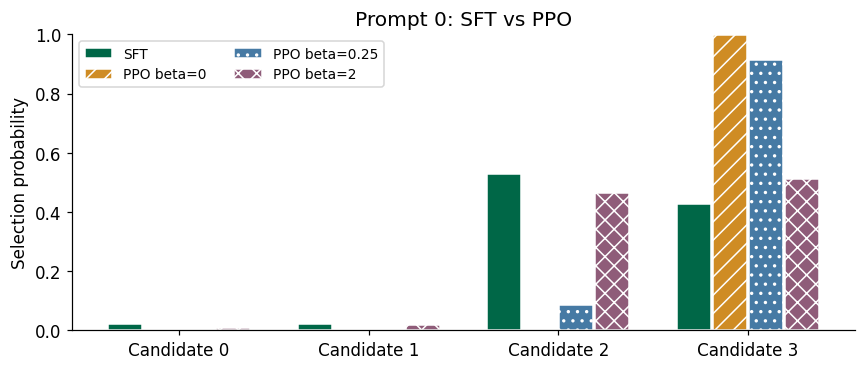

In [12]:
q = 0
show_candidates(q)
comparison = {'candidate': range(N_A),
              'SFT': reference_probs[q].tolist()}
for beta, run in clean_runs.items():
    comparison[f'PPO beta={beta:g}'] = F.softmax(run['logits'][q], -1).tolist()
display(pd.DataFrame(comparison).round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(N_A)
series = [('SFT', reference_probs[q])]
series += [(f'PPO beta={b:g}', F.softmax(clean_runs[b]['logits'][q], -1)) for b in betas]
for i, (name, probs) in enumerate(series):
    ax.bar(positions + (i - 1.5) * .19, probs.numpy(), width=.18,
           color=COLORS[i], label=name, edgecolor='white', hatch=['', '//', '..', 'xx'][i])
ax.set(xticks=positions, xticklabels=[f'Candidate {a}' for a in range(N_A)],
       ylim=(0, 1), ylabel='Selection probability', title=f'Prompt {q}: SFT vs PPO')
ax.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()


### 해석 질문 1
`beta=0`과 `beta=2`의 **보상·KL·답변 선택 확률**을 비교하세요.
KL이 작다는 것은 어떤 기준에 가깝다는 뜻인가요? 그 기준이 항상 가장 좋은 답변인가요?

**답안:**
- **보상:** 기대 clean RM 보상은 SFT 0.775 → `beta=0` 1.162 / `beta=2` 0.862로, KL 패널티가 없을 때 보상이 가장 많이 올랐습니다. 합성 rubric도 `beta=0` 0.972 > `beta=2` 0.881 순입니다.
- **KL:** `beta=0`은 SFT 대비 KL 0.828 nats까지 멀어졌지만 `beta=2`는 0.023 nats로 SFT 정책에 거의 붙어 있습니다(`beta=.25`는 0.510).
- **선택 확률(질문 0, 초등학생에게 중력):** 대상에 맞는 쉬운 답변(후보 3)의 확률이 SFT 0.427 → `beta=0` 0.998인 반면 `beta=2`는 0.513에 그치고, 대학생용 상세 답변(후보 2)이 여전히 0.463입니다.
- **해석:** KL이 작다는 것은 **SFT 기준 정책 π_SFT에 가깝다**는 뜻이지 좋은 답변에 가깝다는 뜻이 아닙니다. 이 실습의 SFT 시연은 의도적으로 불완전해서(질문 0 시연 9:11로 대상에 덜 맞는 답이 더 많음) SFT 자체가 최선이 아니므로, KL을 강하게 걸면 그 불완전함까지 보존됩니다. 반대로 KL은 RM이 틀렸을 때 정책이 보상 모델을 과도하게 착취하지 못하게 막는 안전장치이므로(실험 B 참고), β는 보상 개선과 기준 정책 유지 사이의 trade-off입니다.


## 6. 실험 B — 평가자가 긴 답변에 과도한 점수를 준다면?
두 번째 보상 모델의 학습 선호는 `기존 rubric 점수 + 6 × 길이`로 만듭니다.
이 합성 평가자는 **길지만 틀린 답변**을 선호할 수 있습니다.
데이터 생성 규칙을 바꾸는 실험이며, InstructGPT 평가자가 실제로 이런 편향을 가졌다는 주장이 아닙니다.

같은 특성, 학습 질문, 구조, seed로 보상 모델을 다시 학습합니다.
두 RM은 각각 학습 질문에서 평균 0·표준편차 1로 점수를 고정 정규화하지만 **서로 다른 척도**입니다.
따라서 서로의 보상 절대값으로 품질 순위를 매기지 않습니다.
편향 효과의 주 비교는 `clean PPO(beta=.25)`와 `biased PPO(beta=.25)`입니다.
`biased PPO(beta=0)`은 KL 보호가 없을 때의 추가 비교입니다.


In [13]:
biased_rm, biased_rewards, biased_history = train_reward_model(biased_train)
rm_compare = pd.DataFrame([
    {'RM': 'clean', 'clean-label held-out accuracy': pair_accuracy(clean_rewards, clean_test),
     'length-biased held-out accuracy': pair_accuracy(clean_rewards, biased_test)},
    {'RM': 'length-biased', 'clean-label held-out accuracy': pair_accuracy(biased_rewards, clean_test),
     'length-biased held-out accuracy': pair_accuracy(biased_rewards, biased_test)}])
display(rm_compare.round(3))
biased_runs = {beta: run_ppo(biased_rewards, beta=beta) for beta in [0., .25]}
cross_rows = []
for label, logits in [('SFT', reference_logits),
                      ('Clean PPO beta=.25', clean_runs[.25]['logits']),
                      ('Biased PPO beta=.25', biased_runs[.25]['logits']),
                      ('Biased PPO beta=0', biased_runs[0.]['logits'])]:
    metrics = measure(logits, clean_rewards, 0.)
    metrics['clean_RM_score'] = metrics.pop('reward')
    metrics.pop('objective')
    metrics['biased_RM_score'] = measure(logits, biased_rewards, 0.)['reward']
    cross_rows.append({'policy': label, **metrics})
cross_summary = pd.DataFrame(cross_rows)
display(cross_summary.round(4))


,RM,clean-label held-out accuracy,length-biased held-out accuracy
0,clean,1.000,0.625
1,length-biased,0.667,0.875


,policy,kl,rubric,length,wrong_prob,clean_RM_score,biased_RM_score
0,SFT,0.0000,0.8514,0.3136,0.0225,0.7747,0.1713
1,Clean PPO beta=.25,0.5101,0.9555,0.3090,0.0010,1.1070,0.4378
2,Biased PPO beta=.25,1.0120,0.7540,0.5394,0.3441,0.5812,0.6997
3,Biased PPO beta=0,3.7305,0.4010,0.8751,0.9933,-0.3318,1.1205


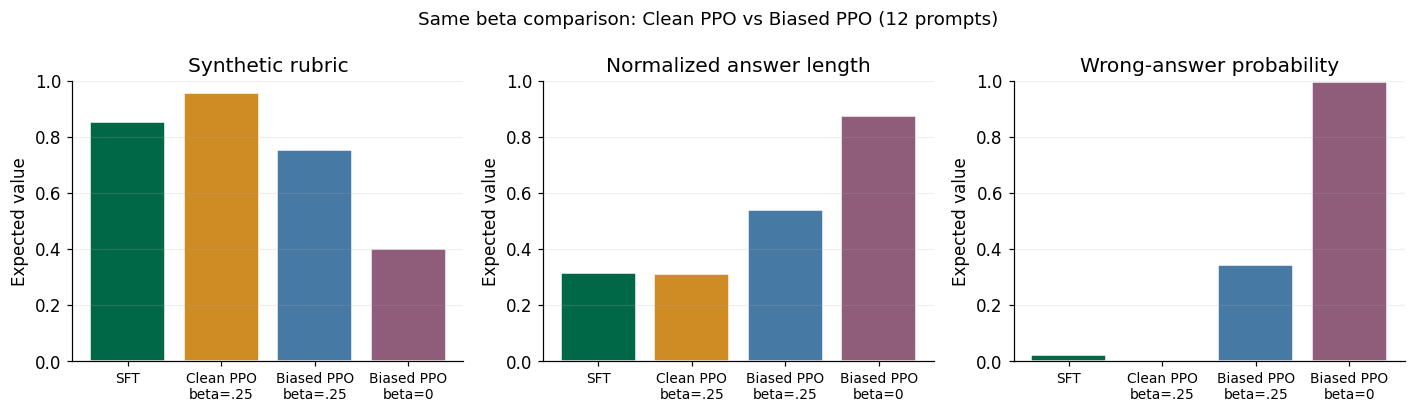

**질문 0: 초등학생에게 중력을 설명해줘.**

- **후보 0:** 오늘 저녁에는 밥과 반찬을 준비하고 식탁을 정리하면 좋겠습니다.

- **후보 1:** 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 중력은 모든 물체를 지구 밖으로 밀어내는 힘이다. 따라서 위 주장은 언제나 확실하며 예외도 없다. 이 설명을 반복하면 더 정확한 답이 된다.

- **후보 2:** 중력은 질량을 가진 물체 사이의 인력이다. 지표면 부근의 자유 낙하 가속도는 약 9.8 m/s²이다.

- **후보 3:** 물건을 지구 쪽으로 끌어당기는 힘이야.

,candidate,synthetic rubric,clean RM,biased RM,biased PPO probability
0,0,0.091,-1.428,-1.534,0.001
1,1,0.406,-0.324,0.992,0.355
2,2,0.795,0.580,0.101,0.225
3,3,0.987,1.192,0.283,0.419


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
names = ['SFT', 'Clean PPO\nbeta=.25', 'Biased PPO\nbeta=.25', 'Biased PPO\nbeta=0']
for ax, metric, title in zip(axes, ['rubric', 'length', 'wrong_prob'],
                            ['Synthetic rubric', 'Normalized answer length', 'Wrong-answer probability']):
    ax.bar(np.arange(4), cross_summary[metric], color=COLORS, edgecolor='white')
    ax.set(xticks=np.arange(4), xticklabels=names, ylim=(0, 1), ylabel='Expected value', title=title)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Same beta comparison: Clean PPO vs Biased PPO (12 prompts)', fontsize=12)
plt.tight_layout()
plt.show()

q = 0
show_candidates(q)
display(pd.DataFrame({'candidate': range(N_A),
                      'synthetic rubric': rubric[q].tolist(),
                      'clean RM': clean_rewards[q].tolist(),
                      'biased RM': biased_rewards[q].tolist(),
                      'biased PPO probability': F.softmax(biased_runs[.25]['logits'][q], -1).tolist()}).round(3))


### 해석 질문 2
같은 `beta=.25`에서 clean PPO와 biased PPO의 합성 rubric·길이·오답 확률을 비교하세요.
학습에 쓰는 RM 보상이 올라도 답변이 좋아졌다고 단정할 수 없는 이유는 무엇인가요?
학습 라벨과 보류 라벨이 같은 편향을 가지면 보류 정확도는 무엇을 놓칠까요?

**답안:**
- **수치 비교 (beta=.25):** clean PPO는 rubric 0.956 / 길이 0.309 / 오답 확률 0.001인데, biased PPO는 rubric 0.754 / 길이 0.539 / 오답 확률 0.344로 SFT(rubric 0.851, 오답 0.023)보다도 나빠졌습니다. KL 보호가 없는 biased PPO(beta=0)는 오답 확률 0.993, rubric 0.401로 거의 항상 길고 틀린 답을 고릅니다.
- **실제 후보 근거:** 질문 0에서 biased RM은 “중력은 모든 물체를 지구 밖으로 밀어내는 힘이다…”를 반복하는 **길지만 틀린 후보 1**에 0.992로 가장 높은 점수를 주고(rubric 0.406), biased PPO는 이 후보를 0.355 확률로 선택합니다.
- **RM 보상 ≠ 품질:** biased PPO(beta=0)는 자기가 학습한 biased RM 점수가 1.121로 가장 높지만 clean RM 점수는 −0.332입니다. RM은 사람 선호의 *대리 지표(proxy)*일 뿐이므로, 정책이 그 RM의 결함(길이 선호)을 최적화하면 보상은 오르는데 실제 품질은 떨어지는 reward hacking(Goodhart)이 일어납니다.
- **보류 정확도의 한계:** biased RM은 같은 편향 라벨의 held-out에서 0.875로 높아 보이지만 clean 라벨 기준으로는 0.667입니다. 보류 데이터가 같은 편향을 공유하면 held-out 정확도는 “평가자를 얼마나 잘 흉내내는가”만 측정할 뿐, 평가자 자체의 체계적 오류(정확성보다 길이를 선호)를 전혀 잡아내지 못합니다.

### 해석 질문 3
실제 LLM에서 이 실습의 질문·후보·정책·critic·RM은 각각 무엇에 대응하나요?
SFT 기준 정책과 PPO의 old 정책의 차이도 설명하세요.
마지막으로 이 실습만으로 결론 내릴 수 없는 내용을 두 가지 적으세요.

**답안:**
- **대응 관계:** 질문 = 사용자 프롬프트 x(API 프롬프트 분포), 후보 4개 = 정책이 토큰 단위로 생성할 수 있는 응답 공간(사실상 무한)의 일부, 정책 `logits[질문, 후보]` = GPT-3를 SFT로 fine-tune한 언어모델 π(y|x), critic `V(x)` = RM으로 초기화한 value 함수(논문에선 토큰별 value와 GAE 사용), RM `wᵀfeature` = SFT 모델에서 마지막 층을 스칼라 헤드로 바꾼 6B 보상 모델(라벨러의 K개 응답 순위로 만든 pairwise 비교로 학습, 논문 §3.5)에 대응합니다.
- **SFT 기준 정책 vs old 정책:** `ref_logp`(π_SFT)는 SFT 직후 한 번 고정되어 PPO 내내 바뀌지 않으며, KL 패널티로 정책이 원래 언어 분포에서 너무 멀어지지 않게 하는 **장기 앵커**입니다. `old_logp`(π_old)는 매 rollout마다 현재 정책으로 갱신되며 확률비 ρ와 clipping에서 **한 번의 업데이트 폭**을 제한하는 단기 기준입니다(PPO, Schulman et al. 2017).
- **결론 내릴 수 없는 것 ①:** 실제 언어모델 성능·일반화. 정책은 12개 질문 ID의 표일 뿐이고 RM 특성(정확성·대상 적합성)은 사람이 미리 넣어준 값이라, 새 프롬프트나 실제 텍스트에서 PPO가 InstructGPT처럼 선호도를 올린다는 근거가 되지 않습니다.
- **결론 내릴 수 없는 것 ②:** 실제 사람 선호·편향의 크기와 PPO-ptx의 효과. 선호 쌍은 합성 규칙(rubric + 6×길이)이며 InstructGPT 라벨러가 이런 편향을 가졌다는 증거가 아니고, 사전학습 데이터 혼합(PPO-ptx)으로 공개 NLP 벤치마크의 alignment tax를 줄이는 효과(논문 §4.2)는 이 실습에 포함되지 않았습니다. 또한 seed 42 한 번의 결과라 변동성도 판단할 수 없습니다.

## 7. 제출 및 자체 점검
- TODO 1–6을 완성한 노트북을 제출합니다. 모든 셀을 위에서부터 다시 실행하고 출력이 남아 있는지 확인하세요.
- 실험 A 그래프와 실험 B 그래프를 포함합니다. 별도 이미지 제출은 필요하지 않습니다.
- 해석 질문 1–3에 답합니다. 각 답안은 3–5문장 정도로 작성하고 관찰한 수치를 사용하세요.

### 평가 기준 (총 100점)
| 항목 | 배점 |
|---|---:|
| SFT와 보상 모델 손실 구현 (TODO 1–2) | 20 |
| PPO 수식 구현 및 검증 (TODO 3–6) | 30 |
| 동일 조건의 실험 A/B 실행 및 그래프 | 20 |
| 관찰값에 근거한 해석과 논문 연결 | 30 |

**권장 시간 배분:** 데이터·SFT 15분 / RM 15분 / PPO 25분 / 비교·해석 20분.
실행 시간과 풀이 시간은 다릅니다. 학습은 작은 CPU 모델이며 환경에 따라 실행 시간이 달라집니다.


In [15]:
# 전체 풀이 후 최종 점검: 새 런타임에서 위에서부터 다시 실행하세요.
for name, run in [('clean', clean_runs[.25]), ('biased', biased_runs[.25])]:
    probabilities = F.softmax(run['logits'], -1)
    assert torch.isfinite(probabilities).all()
    assert torch.allclose(probabilities.sum(-1), torch.ones(N_Q), atol=1e-6)
    assert run['history']['kl'].min() > -1e-5
assert all(not parameter.requires_grad for parameter in clean_rm.parameters())
assert all(not parameter.requires_grad for parameter in biased_rm.parameters())
assert torch.equal(reference_logits, policy_logits.detach())
print('확률 정규화, KL, 고정 RM 및 SFT 기준 정책: passed')


확률 정규화, KL, 고정 RM 및 SFT 기준 정책: passed


## 8. 선택 심화 및 참고 자료
**선택 심화:** 한 번에 한 가지 조건만 바꾸고 결과를 설명하세요.
1. `epsilon=.1`과 `.3` 비교: clipping이 확률비의 강제 제한인지 학습 유인인지 설명하기.
2. 선호 데이터의 길이 가중치 6을 0·2·6으로 비교하기. 바꾼 쌍을 다시 만들고 RM과 PPO를 재학습해야 합니다.
3. seed를 42·43·44로 바꾸고 변동성 비교하기. 한 seed의 결과를 보편적 결론으로 일반화하지 않기.

### 출처
- Ouyang et al. (2022), [Training language models to follow instructions with human feedback, v1](https://arxiv.org/abs/2203.02155v1), §3.1, §3.5, §5.2–5.3. 제공된 논문의 방법과 한계를 바탕으로 설계했습니다.
- Schulman et al. (2017), [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347), §3: clipped objective의 출처.
- [PyTorch probability distributions](https://docs.pytorch.org/docs/stable/distributions.html): `Categorical`로 정책에서 행동 샘플링.
- [Colab FAQ](https://research.google.com/colaboratory/faq.html): 런타임과 자원 안내.

질문·답변·수작업 특성·선호 라벨은 이 과제를 위해 만든 **합성 교육 자료**입니다.
수식 구현용 데이터이며 원논문 데이터나 실제 사람의 평가를 나타내지 않습니다.
